# X-IIoTID — Random Forest (separate model notebook)

**V2 provisional Core-19 network benchmark.** Uses frozen 70/15/15 Core-19 group-disjoint split. Fits preprocessing **only on train**, evaluates **only on validation**, exports confusion matrix, feature importance (where provided), timing, model and metrics.

To run: first execute Notebook **07**, then this notebook. All five models use the same **150,000-row stratified subset of training** for a fair, laptop-friendly pilot; the full **123,125-row validation** is used. You may later change `TRAIN_LIMIT` to `None` in *all five* notebooks for full-training comparisons. The 70/15/15 partition membership is never changed.

**Limitations:** Inputs' gateway measurability and session independence have not been verified. This is not an APT-campaign detector. Reported timing is **laptop timing**, not Raspberry Pi inference.


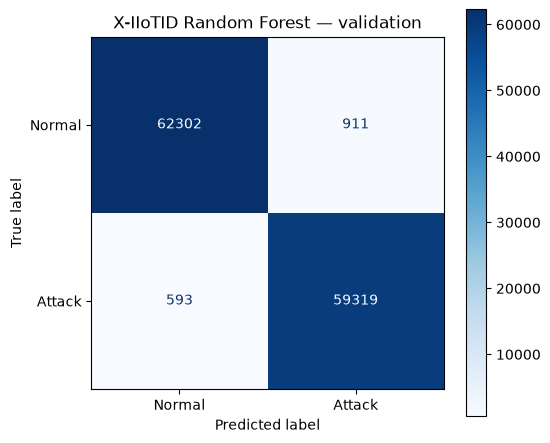

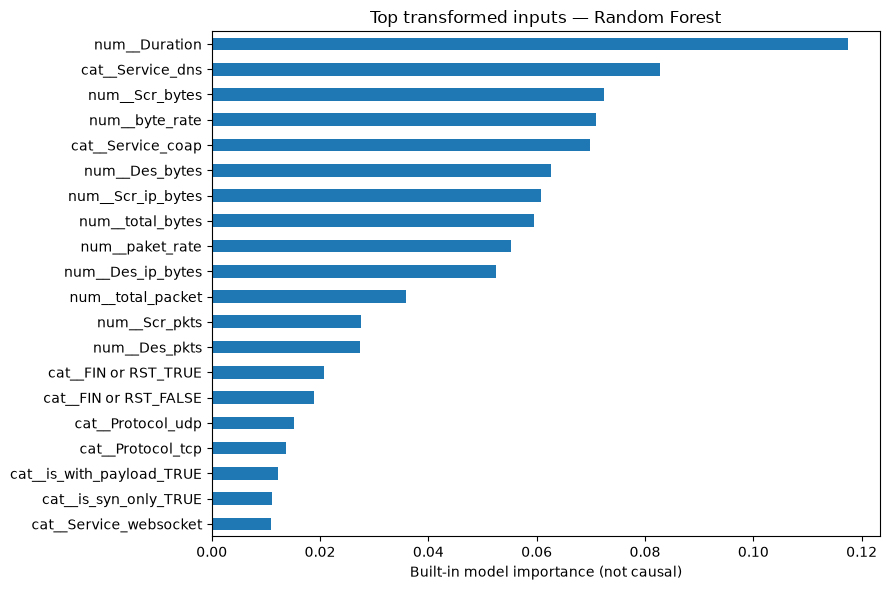


RANDOM_FOREST VALIDATION METRICS — TEST NOT OPENED
        model  train_rows_used  validation_rows  precision_attack  recall_attack  f1_attack  balanced_accuracy  false_positive_rate  fit_seconds  predict_ms_per_1000
random_forest           574585           123125            0.9849         0.9901     0.9875             0.9878               0.0144      65.8960               7.1900
Saved model (local, Git-ignored): D:\J26-CS-336-Network-Flow-V2\network_flow_v2\models\x_iiotid\random_forest_core19_v1.joblib
Saved validation metrics and PNG charts in reports/
{'model': 'random_forest', 'features': 'Core19', 'train_rows_used': 574585, 'validation_rows': 123125, 'precision_attack': 0.9848746471857878, 'recall_attack': 0.9901021498197357, 'f1_attack': 0.9874814802483728, 'balanced_accuracy': 0.9878452786337854, 'false_positive_rate': 0.014411592552164903, 'tn': 62302, 'fp': 911, 'fn': 593, 'tp': 59319, 'fit_seconds': 65.896, 'predict_ms_per_1000': 7.19, 'random_seed': 42, 'frozen_manifest_sh

In [1]:
from pathlib import Path
import sys

ROOT = Path(r"D:\J26-CS-336-Network-Flow-V2\network_flow_v2")
assert ROOT.is_dir(), ROOT

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from x_iiotid_model_runner import execute

# Full training dataset: 574,585 records
TRAIN_LIMIT = None

metrics = execute(
    ROOT,
    "random_forest",
    train_limit=TRAIN_LIMIT
)

print(metrics)

Outputs:
- `reports/audits/x_iiotid_random_forest_validation_v1.csv` and `.json`
- `reports/figures/x_iiotid_random_forest_validation_cm_v1.png`
- Feature-importance chart when estimator supports it
- `models/x_iiotid/random_forest_core19_v1.joblib` (local; Git ignored)

Never run an evaluation on `test` in this notebook. Compare validation metrics across all models in Notebook 13.
